# Unidad 2 — Tarea 5: Serie de calidad del aire
**Asignatura:** Programación avanzada para ciencia de datos (CDC-2420)  
**Fuente:** `pm25_sintetico.csv` (datos sintéticos, 14 días, concentración horaria de PM2.5 en µg/m³).

**Objetivo:** identificar faltantes, datos imposibles y atípicos; comparar estrategias de interpolación temporal y sus efectos estadísticos.  
**Nota:** el archivo original no se modifica. Los valores imputados son estimaciones, no mediciones reales.

## 1. Lectura y diagnóstico inicial

In [1]:
# Importar las bibliotecas utilizadas en el análisis.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Buscar el CSV junto al notebook o dentro de la carpeta datos.
rutas = [Path("datos/pm25_sintetico.csv"), Path("pm25_sintetico.csv"),
         Path("src/datos/pm25_sintetico.csv")]
archivo = next((ruta for ruta in rutas if ruta.exists()), None)
if archivo is None:
    raise FileNotFoundError("Coloca pm25_sintetico.csv junto al notebook o en datos/.")

# Leer el archivo y convertir explícitamente la fecha y hora.
original = pd.read_csv(archivo)
original["fecha_hora"] = pd.to_datetime(original["fecha_hora"], errors="raise")
original = original.sort_values("fecha_hora").reset_index(drop=True)

print("Archivo:", archivo)
print("Dimensiones:", original.shape)
print("Estaciones:", original["estacion"].unique().tolist())
print("Intervalo:", original["fecha_hora"].min(), "a", original["fecha_hora"].max())
print("Faltantes por columna:")
print(original.isna().sum())
print("Duplicados exactos:", original.duplicated().sum())
display(original.head())

Archivo: pm25_sintetico.csv
Dimensiones: (336, 3)
Estaciones: ['CHA']
Intervalo: 2026-03-01 00:00:00 a 2026-03-14 23:00:00
Faltantes por columna:
fecha_hora     0
estacion       0
pm25          35
dtype: int64
Duplicados exactos: 0


,fecha_hora,estacion,pm25
0,2026-03-01 00:00:00,CHA,10.2
1,2026-03-01 01:00:00,CHA,12.1
2,2026-03-01 02:00:00,CHA,9.8
3,2026-03-01 03:00:00,CHA,13.4
4,2026-03-01 04:00:00,CHA,16.9


## 2. Valores físicamente imposibles y faltantes
Una concentración de PM2.5 no puede ser negativa. Se transforma en `NaN` antes del análisis de atípicos y la imputación.

In [2]:
# Contar faltantes originales y valores negativos.
faltantes_originales = int(original["pm25"].isna().sum())
negativos = original["pm25"] < 0
cantidad_negativos = int(negativos.sum())

# Crear copia: nunca alterar la tabla cruda.
datos = original.copy()
datos.loc[negativos, "pm25"] = np.nan

# Convertir la fecha en índice para interpolar según el tiempo transcurrido.
serie = datos.set_index("fecha_hora")["pm25"].sort_index()
assert serie.index.is_unique, "Existen fechas duplicadas: revisar antes de interpolar."
assert serie.index.is_monotonic_increasing
assert not (serie.dropna() < 0).any()

print("Faltantes originales:", faltantes_originales)
print("Concentraciones negativas:", cantidad_negativos)
print("Faltantes tras convertir negativos a NaN:", int(serie.isna().sum()))
print("Filas conservadas:", len(datos))

Faltantes originales: 35
Concentraciones negativas: 1
Faltantes tras convertir negativos a NaN: 36
Filas conservadas: 336


## 3. Detección de atípicos mediante IQR y z-score
Se comparan ambos métodos **sin borrar automáticamente los picos**, porque podrían representar episodios reales de contaminación. Para z-score se usa el umbral `|z| > 3`; para IQR, los límites `Q1 − 1.5·IQR` y `Q3 + 1.5·IQR`.

In [3]:
# Calcular cuartiles y límites del método intercuartílico.
q1, q3 = serie.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
mascara_iqr = (serie < limite_inferior) | (serie > limite_superior)

# Calcular z-score solo para valores observados (ignorar NaN).
z = pd.Series(stats.zscore(serie, nan_policy="omit"), index=serie.index)
mascara_z = z.abs() > 3

# Mostrar mediciones señaladas por al menos uno de los métodos.
atipicos = pd.DataFrame({
    "pm25": serie,
    "atipico_IQR": mascara_iqr,
    "atipico_zscore": mascara_z,
    "z_score": z
})
atipicos = atipicos.loc[mascara_iqr | mascara_z]

print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Límites IQR: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print("Atípicos IQR:", int(mascara_iqr.sum()))
print("Atípicos z-score:", int(mascara_z.sum()))
print("¿Coinciden exactamente?:", bool(mascara_iqr.equals(mascara_z)))
display(atipicos)

Q1=15.60, Q3=29.40, IQR=13.80
Límites IQR: [-5.10, 50.10]
Atípicos IQR: 2
Atípicos z-score: 2
¿Coinciden exactamente?: True


,pm25,atipico_IQR,atipico_zscore,z_score
fecha_hora,,,,
2026-03-03 02:00:00,148.0,True,True,9.347002
2026-03-07 07:00:00,165.5,True,True,10.656850


## 4. Interpolación temporal sin límite y con `limit=3`
Se aplica `method="time"` con `fecha_hora` como índice. La versión limitada rellena **como máximo tres posiciones consecutivas** en cada hueco, con la dirección predeterminada hacia delante. Si existen huecos de más de tres posiciones, algunos valores permanecerán sin imputar.

In [4]:
# Interpolación temporal completa: estima cada hueco entre observaciones.
imputada_completa = serie.interpolate(method="time")

# Interpolación temporal limitada: máximo tres posiciones por bloque de NaN.
imputada_limite3 = serie.interpolate(method="time", limit=3)

# Resumir los resultados sin ocultar valores que aún faltan.
comparacion_huecos = pd.DataFrame({
    "Estrategia": ["Original depurada", "Interpolación temporal completa", "Interpolación temporal limit=3"],
    "Faltantes": [int(serie.isna().sum()),
                  int(imputada_completa.isna().sum()),
                  int(imputada_limite3.isna().sum())]
})
display(comparacion_huecos)

# Identificar bloques consecutivos de valores faltantes.
marcador_bloques = serie.notna().cumsum()
longitudes = serie.isna().groupby(marcador_bloques).sum()
print("Longitud del hueco más largo:", int(longitudes.max()), "horas")
print("Huecos restantes con limit=3:")
display(imputada_limite3[imputada_limite3.isna()].to_frame("pm25"))
assert len(imputada_completa) == len(serie)
assert serie[serie.notna()].equals(imputada_completa[serie.notna()])

,Estrategia,Faltantes
0,Original depurada,36
1,Interpolación temporal completa,0
2,Interpolación temporal limit=3,5


Longitud del hueco más largo: 8 horas
Huecos restantes con limit=3:


,pm25
fecha_hora,
2026-03-05 05:00:00,NaN
2026-03-05 06:00:00,NaN
2026-03-05 07:00:00,NaN
2026-03-05 08:00:00,NaN
2026-03-05 09:00:00,NaN


## 5. Comparación de media y desviación estándar
La comparación *antes* se realiza sobre las mediciones válidas (excluye faltantes y valores negativos). La desviación estándar es muestral (`ddof=1`), que corresponde al comportamiento predeterminado de pandas.

In [5]:
# Construir tabla de estadísticas antes y después de cada estrategia.
resumen_estadistico = pd.DataFrame({
    "Serie": ["Antes (datos válidos)", "Después (sin límite)", "Después (limit=3)"],
    "Observaciones no nulas": [serie.count(), imputada_completa.count(), imputada_limite3.count()],
    "Media (µg/m³)": [serie.mean(), imputada_completa.mean(), imputada_limite3.mean()],
    "Desv. estándar (µg/m³)": [serie.std(), imputada_completa.std(), imputada_limite3.std()]
})
display(resumen_estadistico.round(3))
print(f"Cambio de media tras imputación completa: {imputada_completa.mean()-serie.mean():+.3f} µg/m³")
print(f"Cambio de desviación estándar: {imputada_completa.std()-serie.std():+.3f} µg/m³")

,Serie,Observaciones no nulas,Media (µg/m³),Desv. estándar (µg/m³)
0,Antes (datos válidos),300,23.121,13.383
1,Después (sin límite),336,23.113,12.800
2,Después (limit=3),331,23.112,12.895


Cambio de media tras imputación completa: -0.008 µg/m³
Cambio de desviación estándar: -0.583 µg/m³


## 6. Visualización: serie original e imputada
La curva original contiene interrupciones en las horas sin medición; la serie imputada incorpora estimaciones en esos intervalos. Los valores atípicos se conservan.

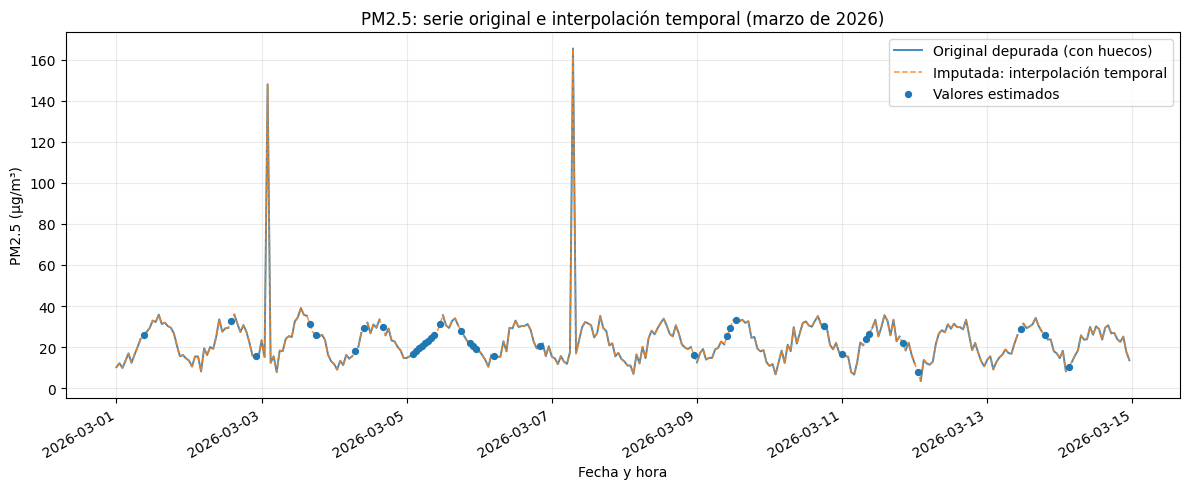

In [6]:
# Comparar ambas series en la misma figura.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie.index, serie, label="Original depurada (con huecos)", linewidth=1.4, alpha=0.85)
ax.plot(imputada_completa.index, imputada_completa,
        label="Imputada: interpolación temporal", linewidth=1.1, linestyle="--", alpha=0.85)

# Resaltar exclusivamente los valores imputados para hacer visibles las diferencias.
fechas_imputadas = serie.index[serie.isna() & imputada_completa.notna()]
ax.scatter(fechas_imputadas, imputada_completa.loc[fechas_imputadas],
           s=18, label="Valores estimados", zorder=3)
ax.set_title("PM2.5: serie original e interpolación temporal (marzo de 2026)")
ax.set_xlabel("Fecha y hora")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Reflexión (media cuartilla)

La interpolación temporal es más apropiada que sustituir todos los faltantes por la media general porque las mediciones de PM2.5 forman una serie cronológica: las concentraciones pueden aumentar o disminuir de una hora a otra. La interpolación utiliza las mediciones cercanas en el tiempo para estimar valores intermedios y conserva mejor la continuidad de las tendencias locales. En cambio, asignar una misma media a todos los huecos introduce valores idénticos en momentos distintos, puede aplanar las variaciones y no respeta la evolución horaria de la contaminación. Esto no significa que la interpolación recupere los valores verdaderos: cuando hay intervalos largos sin observaciones, sus estimaciones son menos confiables. Por eso se comparó la interpolación completa con `limit=3`, que deja algunos huecos sin resolver para hacer visible esa limitación.

Respecto a los picos de PM2.5, **no los eliminaría automáticamente**. Una concentración alta puede deberse a un error del sensor, pero también puede reflejar un episodio real de contaminación, precisamente uno de los eventos más relevantes en un análisis ambiental. Los métodos IQR y z-score identifican observaciones estadísticamente inusuales, no prueban por sí solos que sean incorrectas. Antes de modificar un pico revisaría la calidad del instrumento, las mediciones cercanas, posibles fallas de captura y, si existieran, registros de estaciones vecinas o condiciones meteorológicas. Sin evidencia de error, conservaría los picos y documentaría su presencia. En contraste, una concentración negativa sí es físicamente imposible y se convirtió en faltante antes de interpolar. Así se evita confundir una regla física verificable con una decisión estadística que requiere contexto.

## 8. Bitácora de decisiones y comprobaciones finales

In [7]:
# Registrar las decisiones metodológicas para que el análisis sea reproducible.
bitacora = pd.DataFrame([
    {"Situación": "Valores originalmente faltantes", "Cantidad": faltantes_originales,
     "Decisión": "Conservar como NaN antes de interpolar"},
    {"Situación": "Concentraciones negativas", "Cantidad": cantidad_negativos,
     "Decisión": "Convertir a NaN por imposibilidad física"},
    {"Situación": "Atípicos detectados por IQR", "Cantidad": int(mascara_iqr.sum()),
     "Decisión": "Conservar; requieren verificación externa"},
    {"Situación": "Atípicos detectados por z-score", "Cantidad": int(mascara_z.sum()),
     "Decisión": "Conservar; no son necesariamente errores"},
    {"Situación": "Huecos después de limit=3", "Cantidad": int(imputada_limite3.isna().sum()),
     "Decisión": "Documentar límites de la imputación"},
])
display(bitacora)

# Verificaciones de conservación de datos y coherencia de las imputaciones.
assert len(serie) == len(original) == len(imputada_completa) == len(imputada_limite3)
assert not (serie.dropna() < 0).any()
assert (imputada_completa[serie.notna()] == serie[serie.notna()]).all()
assert (imputada_limite3[serie.notna()] == serie[serie.notna()]).all()
print("Verificaciones finales correctas. El archivo CSV original permanece intacto.")

,Situación,Cantidad,Decisión
0,Valores originalmente faltantes,35,Conservar como NaN antes de interpolar
1,Concentraciones negativas,1,Convertir a NaN por imposibilidad física
2,Atípicos detectados por IQR,2,Conservar; requieren verificación externa
3,Atípicos detectados por z-score,2,Conservar; no son necesariamente errores
4,Huecos después de limit=3,5,Documentar límites de la imputación


Verificaciones finales correctas. El archivo CSV original permanece intacto.
